In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))

from src.features import build_features, IN_SCOPE_TYPES, SET_B_EXTRA

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "paysim.csv"
OUT_DIR = PROJECT_ROOT / "data" / "processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
usecols = ["step", "type", "amount", "oldbalanceOrg", "isFraud", "isFlaggedFraud"]
dtypes = {
    "step": "uint16", "type": "category", "amount": "float64",
    "oldbalanceOrg": "float64", "isFraud": "int8", "isFlaggedFraud": "int8",
}

raw = pd.read_csv(DATA_PATH, usecols=usecols, dtype=dtypes)
raw = raw[raw["type"].isin(IN_SCOPE_TYPES)].copy()
raw["type"] = raw["type"].cat.remove_unused_categories()
raw = raw.reset_index(names="orig_row")

print(raw.shape, "| fraud:", int(raw["isFraud"].sum()))

(2770409, 7) | fraud: 8213


In [3]:
feats = build_features(raw)

data = pd.concat(
    [raw[["orig_row", "step", "type", "amount", "isFlaggedFraud", "isFraud"]], feats],
    axis=1,
).rename(columns={"isFlaggedFraud": "rule_flag"})

print("Missing values:", int(data.isna().sum().sum()))
data.head()

Missing values: 0


,orig_row,step,type,amount,rule_flag,isFraud,log_amount,hour,hour_sin,hour_cos,is_transfer,amt_to_balance,empties_account,old_zero
0,2,1,TRANSFER,181.00,0,1,5.204007,0,0.0,1.0,1,1.0,1,0
1,3,1,CASH_OUT,181.00,0,1,5.204007,0,0.0,1.0,0,1.0,1,0
2,15,1,CASH_OUT,229133.94,0,0,12.342067,0,0.0,1.0,0,10.0,0,0
3,19,1,TRANSFER,215310.30,0,0,12.279840,0,0.0,1.0,1,10.0,0,0
4,24,1,TRANSFER,311685.89,0,0,12.649755,0,0.0,1.0,1,10.0,0,0


In [4]:
print("Feature means by class (0 = genuine, 1 = fraud):")
print(data.groupby("isFraud")[SET_B_EXTRA].mean().round(3))
print()
data[["log_amount", "hour", "hour_sin", "hour_cos", "amt_to_balance"]].describe().T.round(3)

Feature means by class (0 = genuine, 1 = fraud):
         amt_to_balance  empties_account  old_zero
isFraud                                           
0                 3.013            0.000     0.474
1                 0.990            0.976     0.005



,count,mean,std,min,25%,50%,75%,max
log_amount,2770409.0,11.928,1.233,0.0,11.326,12.051,12.634,18.342
hour,2770409.0,14.467,3.869,0.0,11.000,15.000,18.000,23.000
hour_sin,2770409.0,-0.359,0.631,-1.0,-0.966,-0.500,0.259,1.000
hour_cos,2770409.0,-0.451,0.519,-1.0,-0.866,-0.707,-0.000,1.000
amt_to_balance,2770409.0,3.007,4.076,0.0,0.000,0.233,6.494,10.000


In [5]:
TRAIN_END = 504   # days 1-21  (steps 1-504)
VAL_END = 624     # days 22-26 (steps 505-624); test = steps 625-743

data["split"] = pd.cut(
    data["step"],
    bins=[0, TRAIN_END, VAL_END, int(data["step"].max())],
    labels=["train", "val", "test"],
)

summary = data.groupby("split", observed=True).agg(
    rows=("isFraud", "size"),
    fraud=("isFraud", "sum"),
    first_step=("step", "min"),
    last_step=("step", "max"),
)
summary["fraud_rate_%"] = (summary["fraud"] / summary["rows"] * 100).round(3)
summary["share_of_rows_%"] = (summary["rows"] / summary["rows"].sum() * 100).round(1)
summary

,rows,fraud,first_step,last_step,fraud_rate_%,share_of_rows_%
split,,,,,,
train,2646363,5621,1,504,0.212,95.5
val,85954,1264,505,624,1.471,3.1
test,38092,1328,625,743,3.486,1.4


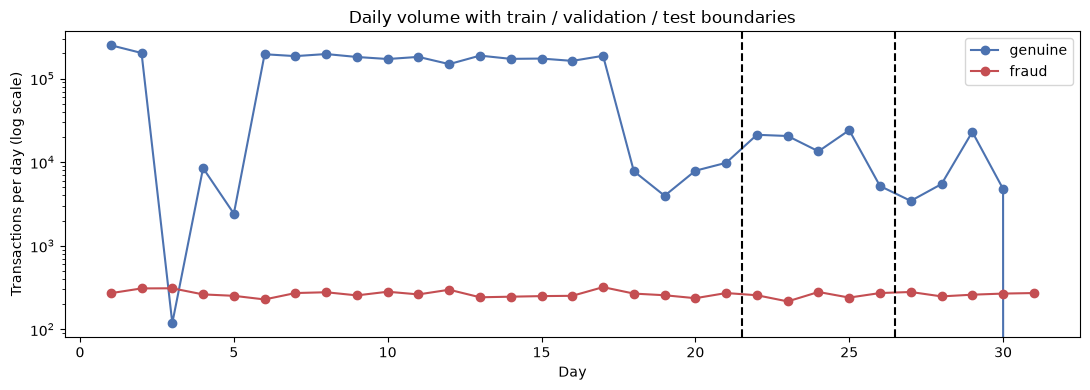

In [6]:
day = (data["step"] - 1) // 24 + 1
daily = pd.crosstab(day, data["isFraud"])
daily.columns = ["genuine", "fraud"]

ax = daily.plot(figsize=(11, 4), logy=True, marker="o", color=["#4C72B0", "#C44E52"])
for x in [TRAIN_END / 24 + 0.5, VAL_END / 24 + 0.5]:
    ax.axvline(x, color="black", linestyle="--")
ax.set_xlabel("Day")
ax.set_ylabel("Transactions per day (log scale)")
ax.set_title("Daily volume with train / validation / test boundaries")
plt.tight_layout()
plt.savefig("../reports/figures/05_daily_counts_and_splits.png", dpi=150)
plt.show()

In [7]:
train = data[data["split"] == "train"]
val = data[data["split"] == "val"]
test = data[data["split"] == "test"]

assert len(train) + len(val) + len(test) == len(data), "rows lost or duplicated"
assert train["step"].max() < val["step"].min(), "train and val overlap in time"
assert val["step"].max() < test["step"].min(), "val and test overlap in time"
assert set(train["orig_row"]).isdisjoint(val["orig_row"])
assert set(val["orig_row"]).isdisjoint(test["orig_row"])
assert data.isna().sum().sum() == 0, "missing values"
print("All checks passed.")

All checks passed.


In [8]:
for name, part in [("train", train), ("val", val), ("test", test)]:
    part = part.drop(columns="split").reset_index(drop=True)
    part.to_parquet(OUT_DIR / f"{name}.parquet", index=False)
    size_mb = (OUT_DIR / f"{name}.parquet").stat().st_size / 1024**2
    print(f"{name:<6} rows={len(part):>9,}  fraud={int(part['isFraud'].sum()):>6,}  file={size_mb:.1f} MB")

check = pd.read_parquet(OUT_DIR / "train.parquet")
print("\nReloaded train:", check.shape)
print(check.dtypes)

train  rows=2,646,363  fraud= 5,621  file=45.6 MB
val    rows=   85,954  fraud= 1,264  file=1.9 MB
test   rows=   38,092  fraud= 1,328  file=0.8 MB

Reloaded train: (2646363, 14)
orig_row              int64
step                 uint16
type               category
amount              float64
rule_flag              int8
isFraud                int8
log_amount          float32
hour                   int8
hour_sin            float32
hour_cos            float32
is_transfer            int8
amt_to_balance      float32
empties_account        int8
old_zero               int8
dtype: object


In [9]:
day = (data["step"] - 1) // 24 + 1
daily = pd.crosstab(day, data["isFraud"])
daily.columns = ["genuine", "fraud"]
daily["fraud_rate_%"] = (daily["fraud"] / (daily["genuine"] + daily["fraud"]) * 100).round(2)
print(daily.loc[15:])

last_genuine = int(data.loc[data["isFraud"] == 0, "step"].max())
after = data[data["step"] > last_genuine]
print("\nLast step containing any genuine row:", last_genuine)
print("Rows after that step -> fraud:", int(after["isFraud"].sum()), "| genuine:", int((after["isFraud"] == 0).sum()))

      genuine  fraud  fraud_rate_%
step                              
15     173701    250          0.14
16     162892    252          0.15
17     187460    320          0.17
18       7800    268          3.32
19       3967    256          6.06
20       7906    236          2.90
21       9836    272          2.69
22      21273    256          1.19
23      20574    216          1.04
24      13494    280          2.03
25      24163    240          0.98
26       5186    272          4.98
27       3442    280          7.52
28       5476    248          4.33
29      23053    260          1.12
30       4793    268          5.30
31          0    272        100.00

Last step containing any genuine row: 718
Rows after that step -> fraud: 296 | genuine: 0


In [10]:
g = data[data["isFraud"] == 0]
regime = np.where(g["step"] <= 408, "days 1-17", "days 18-31")

compare = g.groupby(regime).agg(
    rows=("step", "size"),
    mean_log_amount=("log_amount", "mean"),
    transfer_share=("is_transfer", "mean"),
    night_share_0_7=("hour", lambda h: (h < 8).mean()),
    old_zero=("old_zero", "mean"),
    amt_to_balance=("amt_to_balance", "mean"),
)
compare.round(3)

,rows,mean_log_amount,transfer_share,night_share_0_7,old_zero,amt_to_balance
days 1-17,2611233,11.927,0.190,0.007,0.478,2.993
days 18-31,150963,11.887,0.222,0.025,0.406,3.365


In [11]:
from src.evaluate import evaluate

rng = np.random.default_rng(0)
for name, part in [("train", train), ("val", val), ("test", test)]:
    r = evaluate(part["isFraud"], rng.random(len(part)))
    print(f"{name:<6}", {k: round(v, 4) for k, v in r.items()})

train  {'roc_auc': 0.4999, 'pr_auc_raw': 0.0021, 'pr_auc_baseline': 0.0021, 'pr_auc_adj': 0.0021, 'recall@0.1%FPR': 0.0014, 'recall@1%FPR': 0.0105}
val    {'roc_auc': 0.4987, 'pr_auc_raw': 0.0144, 'pr_auc_baseline': 0.0147, 'pr_auc_adj': 0.0021, 'recall@0.1%FPR': 0.0008, 'recall@1%FPR': 0.0087}
test   {'roc_auc': 0.4961, 'pr_auc_raw': 0.0346, 'pr_auc_baseline': 0.0349, 'pr_auc_adj': 0.0021, 'recall@0.1%FPR': 0.0, 'recall@1%FPR': 0.0098}


## Decisions (Phase 3): split and evaluation protocol
- Time-based split: train = steps 1-504 (days 1-21), val = 505-624, test = 625-743. Files saved unscaled and unresampled; scaling/SMOTE are fitted on training data inside pipelines in Phase 4.
- Fraud rate differs by split (train 0.212%, val 1.471%, test 3.486%): fraud is steady at ~250-320/day while genuine volume collapses after day 17 (simulator artefact; the last steps appear to contain only fraud - verified in Cell 9).
- Consequence: raw PR-AUC and precision are not comparable across splits.
- Protocol: rank models on validation PR-AUC reweighted to the training fraud rate (pr_auc_adj); cross-check with ROC-AUC and recall at 0.1%/1% FPR; report raw PR-AUC with its baseline; touch the test set once.
- Limitations: genuine traffic volume shifts mid-simulation; adjusted PR-AUC assumes genuine rows are otherwise representative.
